In [1]:
import numpy as np
from trajectory_utils import extract_trajectory_frames, filter_trajectory_frames, filter_trajectory_by_indices, compute_trajectory_deltas
from optical_flow_utils import extract_video_frames, compute_optical_flow, filter_keyframes_by_flow, aggregate_optical_flow
from common_utils import angular_difference


In [2]:
# --- SAMPLE SELECTION ---
# Choose which video sample to analyze: "sample_1", "sample_2", ..., "sample_7"
sample_name = "sample_1"

# --- KEYFRAME SELECTION PARAMETERS ---
# Toggle dynamic motion-driven keyframing vs. fixed-interval baseline (ablation study)
keyframe_mode = "dynamic"  # Options: "dynamic" (motion-driven), "fixed" (fixed frame stride)
fixed_interval = 30        # Frame stride used when keyframe_mode == "fixed" (baseline)

# Dynamic mode settings:
# Condition A: Cumulative 2D pixel displacement (LK translation magnitude) required to trigger a new keyframe
flow_magnitude_threshold = 120.0  # pixels (LK translation magnitude gives 16.95 deg)

# Condition B: Turn angle trigger (Set to None to isolate pure translation magnitude)
angle_threshold_deg = None  # Disabled (None gives lowest error of 16.95 deg)

# Guard bounds: Minimum and maximum frame thresholds
min_interval = 4   # Minimum frames between keyframes (guards against 1-frame glitch bursts)
max_interval = 40  # Maximum frames between keyframes (timeout safety valve for pauses)

# --- CAMERA POSE & WORKING DISTANCE PARAMETERS ---
# Toggle working distance tilt projection vs. pure linear translation (ablation study)
use_working_distance = True  # Set to False to test pure linear translation without angular tilt projection

# Camera working distance (in mm) for virtual landmark projection
working_distance = 25.0  # mm


In [3]:
import os

# Resolve video and trajectory file in the selected sample directory
sample_dir = os.path.join("dataset", sample_name)
input_video = os.path.join(sample_dir, f"{sample_name}.mp4")
json_file = os.path.join(sample_dir, f"{sample_name}_traj.json")

#input_video = "dataset/sample_1/sample_1_slicer_sim.mp4"
#json_file = "dataset/sample_1/sample_1_traj.json"

# Fallback auto-discovery if files are named differently
if not os.path.exists(input_video):
    video_files = [f for f in os.listdir(sample_dir) if f.endswith(".mp4")]
    if video_files:
        input_video = os.path.join(sample_dir, video_files[0])
    else:
        raise FileNotFoundError(f"No .mp4 video found in {sample_dir}")

if not os.path.exists(json_file):
    traj_files = [f for f in os.listdir(sample_dir) if f.endswith("_traj.json")]
    if traj_files:
        json_file = os.path.join(sample_dir, traj_files[0])
    else:
        raise FileNotFoundError(f"No _traj.json file found in {sample_dir}")
print(f"Selected Sample: {sample_name}")
print(f"  Video:         {input_video}")
print(f"  Trajectory:    {json_file}")

# Load video frames (reusing cached frames if analyzing the same sample)
if globals().get("current_sample_name") != sample_name or "video_frames" not in globals():
    video_frames = extract_video_frames(input_video)
    current_sample_name = sample_name
    print(f"Successfully extracted {len(video_frames)} frames.")
else:
    print(f"Using {len(video_frames)} frames already in memory for {sample_name}.")

# Run Lucas-Kanade optical flow on all extracted frames (using robust feature median)
optical_flow_results = compute_optical_flow(video_frames)
print(f"Number of raw optical flow frame-transitions: {len(optical_flow_results)}")

# Select keyframes based on the chosen mode (dynamic vs fixed)
if keyframe_mode == "dynamic":
    keyframe_indices = filter_keyframes_by_flow(
        optical_flow_results,
        pixel_threshold=flow_magnitude_threshold,
        angle_threshold_deg=angle_threshold_deg,
        min_interval=min_interval,
        max_interval=max_interval
    )
    print(f"Selected {len(keyframe_indices)} dynamic keyframes (motion threshold: {flow_magnitude_threshold} px, min: {min_interval} fms, max: {max_interval} fms).")
else:
    # Fixed frame stride (baseline)
    keyframe_indices = list(range(0, len(video_frames), fixed_interval))
    print(f"Selected {len(keyframe_indices)} fixed keyframes (stride: every {fixed_interval} frames).")

# Aggregate optical flow across the selected keyframe windows
aggregated_flow = aggregate_optical_flow(optical_flow_results, keyframe_indices=keyframe_indices)
num_aggregated = len(aggregated_flow['flow_x'])
print(f"Number of aggregated flow intervals: {num_aggregated}")


Selected Sample: sample_1
  Video:         videos/sample_1/sample_1.mp4
  Trajectory:    videos/sample_1/sample_1_traj.json
Reading video: videos/sample_1/sample_1.mp4
Successfully extracted 817 frames.
Computing optical flow across 817 frames (Feature median)...
Obtaining circle mask...
Number of raw optical flow frame-transitions: 816
Selected 39 dynamic keyframes (motion threshold: 120.0 px, min: 4 fms, max: 40 fms).
Number of aggregated flow intervals: 38


In [4]:
# Load poses from the sample's trajectory file
all_poses = extract_trajectory_frames(json_file)
print(f"Number of camera poses read: {len(all_poses)}")

# Sample camera poses at the EXACT milestones chosen by the video
poses = filter_trajectory_by_indices(all_poses, keyframe_indices)
print(f"Number of camera poses matched to video keyframes: {len(poses)}")

# Calculate local translations in camera view (with working_distance toggle)
mode_str = f"apparent motion at working_distance={working_distance}mm (translation + tilt)" if use_working_distance else "pure linear translation (no tilt)"
print(f"Computing camera trajectory deltas: {mode_str}")
trajectory_data = compute_trajectory_deltas(
    poses,
    working_distance=working_distance,
    use_working_distance=use_working_distance
)

pose_angles = trajectory_data["angles"]
dx_local = trajectory_data["dx"]
dy_local = trajectory_data["dy"]
dz_local = trajectory_data["dz"]


Number of camera poses read: 817
Number of camera poses matched to video keyframes: 39
Computing camera trajectory deltas: apparent motion at working_distance=25.0mm (translation + tilt)


Total transition intervals: 38
Mean Angular Direction Error: 23.02 degrees
Std Angular Direction Error:  28.29 degrees
Max Angular Direction Error: 158.38 degrees (at frame 476)


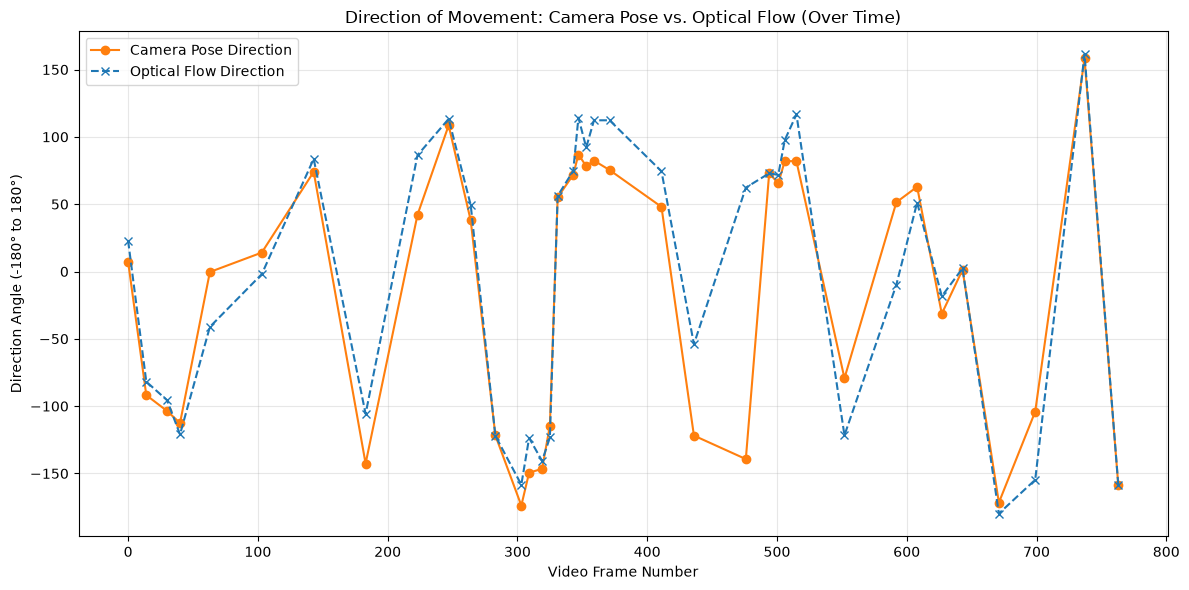

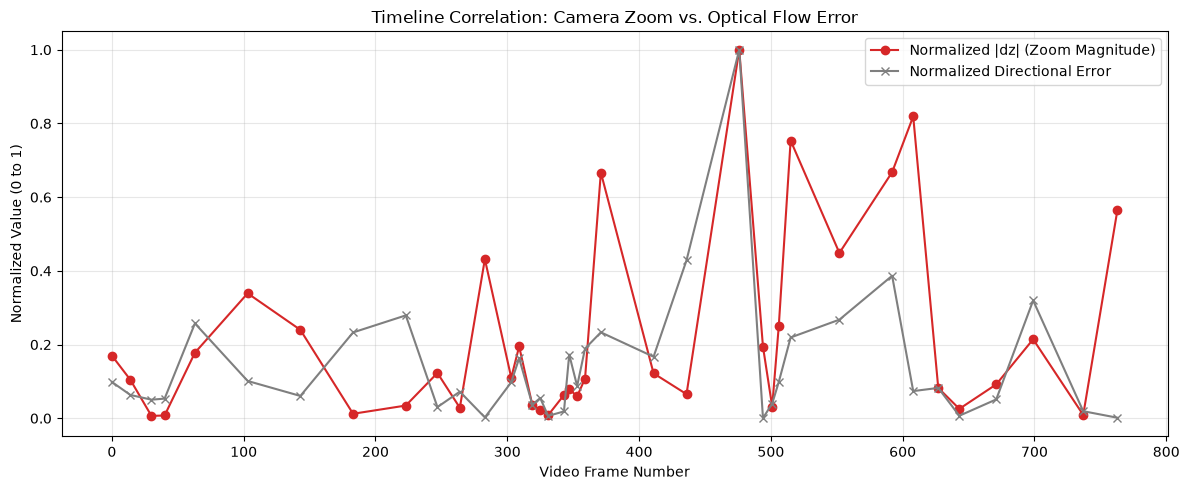

In [5]:
# --- DIRECTIONAL COMPARISON ---
# We compare angles instead of magnitudes because depth scaling breaks magnitude comparisons.

flow_angles = aggregated_flow["angles"]

# Safety check: Ensure pose length matches flow length
min_len = min(len(pose_angles), len(flow_angles))
pose_angles_matched = pose_angles[:min_len]
flow_angles_matched = flow_angles[:min_len]

# Map each transition interval to its starting video frame number
frame_numbers = keyframe_indices[:min_len]

errors_in_rad = angular_difference(pose_angles_matched, flow_angles_matched)
mean_error_deg = np.degrees(np.mean(errors_in_rad))
std_error_deg = np.degrees(np.std(errors_in_rad))
max_error_deg = np.degrees(np.max(errors_in_rad))
max_error_frame = frame_numbers[np.argmax(errors_in_rad)]

print(f"Total transition intervals: {min_len}")
print(f"Mean Angular Direction Error: {mean_error_deg:.2f} degrees")
print(f"Std Angular Direction Error:  {std_error_deg:.2f} degrees")
print(f"Max Angular Direction Error: {max_error_deg:.2f} degrees (at frame {max_error_frame})")

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(frame_numbers, np.degrees(pose_angles_matched), label="Camera Pose Direction", marker="o", linestyle="-", color="tab:orange")
plt.plot(frame_numbers, np.degrees(flow_angles_matched), label="Optical Flow Direction", marker="x", linestyle="--", color="tab:blue")
plt.xlabel("Video Frame Number")
plt.ylabel("Direction Angle (-180° to 180°)")
plt.title("Direction of Movement: Camera Pose vs. Optical Flow (Over Time)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# --- ERROR VS ZOOM OVER TIME ---
import matplotlib.pyplot as plt
import numpy as np

# Extract the absolute Z-translation and ensure lengths match
dz_abs = np.abs(dz_local[:min_len])

# Normalize both arrays to a [0, 1] scale for direct comparison
dz_norm = dz_abs / np.max(dz_abs) if np.max(dz_abs) != 0 else dz_abs
errors_norm = errors_in_rad / np.max(errors_in_rad) if np.max(errors_in_rad) != 0 else errors_in_rad

# Map each transition interval to its starting video frame number
frame_numbers = keyframe_indices[:min_len]

plt.figure(figsize=(12, 5))
plt.plot(frame_numbers, dz_norm, label="Normalized |dz| (Zoom Magnitude)", marker="o", color="tab:red")
plt.plot(frame_numbers, errors_norm, label="Normalized Directional Error", marker="x", color="tab:gray")

plt.xlabel("Video Frame Number")
plt.ylabel("Normalized Value (0 to 1)")
plt.title("Timeline Correlation: Camera Zoom vs. Optical Flow Error")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
